# C_02 — Giant impacts and final melting conditions (sulfur workflow)

Read the provisional small/global events from `C_01_small_impact_s.ipynb`. Qualifying giant impacts are reclassified from `global` to `partial` after global-melting properties have been calculated; the required melt fraction is retained. All small, global and partial events are exported in the final event table consumed by `D_01_differentiation_s.ipynb`.

**Input:** `Tables/05_small_global_impact_events_S.xlsx`  
**Output:** `Tables/05_impact_events_S.xlsx`

Run from the project root or `notebooks/work_flow_S`.


In [1]:
# Reclassify qualifying global events as partial melting.
PROJECT_ROOT = None
WORKFLOW_DIR = None
INTERMEDIATE_FILE = None
PARAMETER_FILE = None
GLOBAL_MASS_THRESHOLD = 0.1 # Must equal C_01
IMPACT_RATIO_RANGE = (0.1, 0.5) # Must equal C_01
PARTIAL_PRESSURE_RATIO = 0.6 # Independent partial-melting pressure fraction
OUTPUT_FILE = None


In [2]:
import matplotlib.pyplot as plt
import json
import numpy as np
import pandas as pd
import sys
from matplotlib.lines import Line2D
from pathlib import Path

working_dir = Path.cwd()
project_root = (Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT is not None
                else next((p for p in (working_dir, *working_dir.parents)
                           if (p / "src" / "accrediff").is_dir()), None))
if project_root is None:
    raise RuntimeError("Could not locate the AccreDiff repository root.")
workflow_dir = (Path(WORKFLOW_DIR).expanduser().resolve() if WORKFLOW_DIR is not None
                else project_root / 'kong_2027_backup' / 'work_flow_S')

sys.path.insert(0, str(project_root / 'src'))
import accrediff as ad


# ── Plot style ──────────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": False,
    "ytick.right": False,
    "figure.dpi": 150,
})

print(f"Project root : {project_root}")
print("Setup complete.")


Project root : /Users/kong/Research/code_zju/AccreDiff
Setup complete.


## 1. Load provisional events


In [3]:
intermediate_file = Path(INTERMEDIATE_FILE) if INTERMEDIATE_FILE is not None else workflow_dir / 'Tables' / '05_small_global_impact_events_S.xlsx'
if not intermediate_file.is_file():
    raise FileNotFoundError(
        f'Provisional impact events not found: {intermediate_file}. '
        'Run C_01_small_impact_s.ipynb first.'
    )
data_dict = pd.read_excel(intermediate_file, sheet_name=None)
if not data_dict:
    raise ValueError(f'No planet sheets found in {intermediate_file}.')
required_event_columns = {
    'Time', 'target_id', 'impactor_id', 'm_target', 'm_impactor',
    'Mass', 'Impact ratio', 'events', 'P_equil', 'T_equil', 'k_mantle',
}
for key, event_table in data_dict.items():
    missing = required_event_columns - set(event_table.columns)
    if missing:
        raise ValueError(f'{key} lacks required event columns: {sorted(missing)}')
    if event_table.empty:
        raise ValueError(f'{key} contains no impact events.')
    unexpected = set(event_table['events'].dropna().unique()) - {'small', 'global'}
    if unexpected:
        raise ValueError(f'{key} contains unexpected provisional event types: {sorted(unexpected)}')
first_planet = next(iter(data_dict))
print(f'Loaded provisional events: {intermediate_file}')


Loaded provisional events: /Users/kong/Research/code_zju/AccreDiff/kong_2027_backup/work_flow_S/Tables/05_small_global_impact_events_S.xlsx


## 2. Update giant-impact partial melting

The global classification runs first so that source events retain their computed melt fraction when their equilibration P/T is replaced by the partial-melt-pool conditions. C_02 reads the parameter record exported by C_01 so both passes use the same mass, ratio and pressure settings. The batch interface will later move these settings into the scenario configuration.


In [4]:
parameter_file = Path(PARAMETER_FILE) if PARAMETER_FILE is not None else workflow_dir / 'Tables' / '05_impact_parameters_S.json'
if not parameter_file.is_file():
    raise FileNotFoundError(f'C_01 impact parameters not found: {parameter_file}')
impact_parameters = json.loads(parameter_file.read_text())
if float(impact_parameters['GLOBAL_MASS_THRESHOLD']) != GLOBAL_MASS_THRESHOLD or tuple(impact_parameters['IMPACT_RATIO_RANGE']) != tuple(IMPACT_RATIO_RANGE):
    raise ValueError('C_01/C_02 giant-impact classification parameters differ.')
if not 0.0 < GLOBAL_MASS_THRESHOLD or not 0.0 < PARTIAL_PRESSURE_RATIO <= 1.0:
    raise ValueError('Invalid shared C-stage impact parameters.')
if len(IMPACT_RATIO_RANGE) != 2 or not 0.0 <= IMPACT_RATIO_RANGE[0] < IMPACT_RATIO_RANGE[1] <= 1.0:
    raise ValueError('Invalid impact-ratio range from C_01.')
print(f'Using C_01 impact parameters: {parameter_file}')


Using C_01 impact parameters: /Users/kong/Research/code_zju/AccreDiff/kong_2027_backup/work_flow_S/Tables/05_impact_parameters_S.json


In [5]:
for key, event_table in data_dict.items():
    data_dict[key] = ad.update_partial_melting_process(
        event_table,
        Mtotal=GLOBAL_MASS_THRESHOLD,
        ratio=list(IMPACT_RATIO_RANGE),
        events='partial',
        P_ratio=PARTIAL_PRESSURE_RATIO,
    )

allowed_events = {'small', 'global', 'partial'}
required_event_columns = {
    'Time', 'target_id', 'impactor_id', 'm_target', 'm_impactor',
    'Mass', 'Impact ratio', 'events', 'P_equil', 'T_equil', 'k_mantle',
}
for key, event_table in data_dict.items():
    missing = required_event_columns - set(event_table.columns)
    if missing:
        raise ValueError(f'{key} lacks required event columns: {sorted(missing)}')
    if event_table[['target_id', 'impactor_id']].isna().any().any():
        raise ValueError(f'{key} contains missing target or impactor IDs.')
    unexpected = set(event_table['events'].dropna().unique()) - allowed_events
    if unexpected:
        raise ValueError(f'{key} contains unexpected event types: {sorted(unexpected)}')
    pt = event_table[['P_equil', 'T_equil']].to_numpy(dtype=float)
    if not np.isfinite(pt).all() or (pt <= 0.0).any():
        raise ValueError(f'{key} contains invalid equilibration P/T values.')
    melting = event_table['events'].isin({'global', 'partial'})
    melt_fraction = event_table.loc[melting, 'k_mantle'].to_numpy(dtype=float)
    if not np.isfinite(melt_fraction).all() or ((melt_fraction < 0.0) | (melt_fraction > 1.0)).any():
        raise ValueError(f'{key} contains invalid global/partial melt fractions.')

print("Partial melting update and validation complete.")
print(f"Event type counts ({first_planet}):")
print(data_dict[first_planet]['events'].value_counts())


Partial melting update and validation complete.
Event type counts (planets_1):
events
small      115
global       9
partial      3
Name: count, dtype: int64


## 3. Inspect mass evolution by final event type


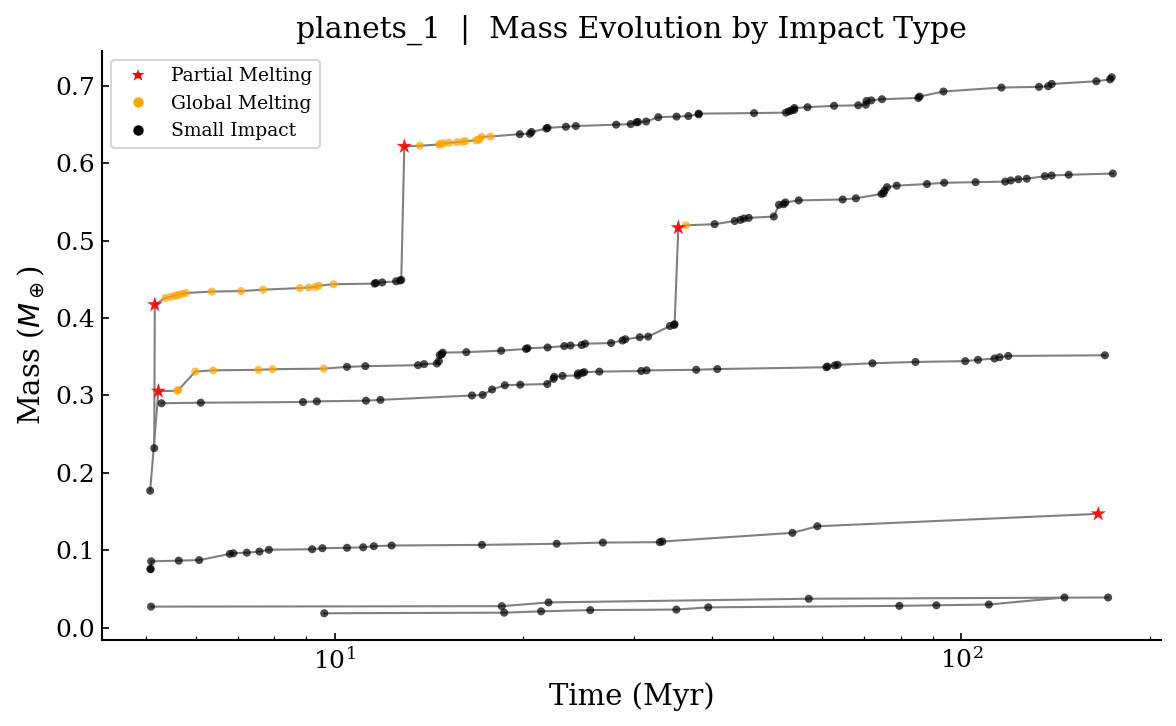

In [6]:
legend_handles = [
    Line2D([0], [0], marker='*', color='w', label='Partial Melting',
           markerfacecolor='red', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Global Melting',
           markerfacecolor='orange', markersize=6),
    Line2D([0], [0], marker='o', color='w', label='Small Impact',
           markerfacecolor='black', markersize=6),
]

fig, ax = plt.subplots(figsize=(8, 5))

for key in data_dict.keys():
    df1        = data_dict[key]
    planet_id  = df1['target_id'].iloc[-1]
    df_planet  = df1[df1['target_id'] == planet_id]

    x = df_planet['Time']
    y = df_planet['Mass']

    mask_small   = df_planet['events'] == 'small'
    mask_global  = df_planet['events'] == 'global'
    mask_partial = df_planet['events'] == 'partial'

    ax.plot(x, y, c='grey', linewidth=1, zorder=3)
    ax.scatter(x[mask_small],   y[mask_small],   c='black',  s=15, alpha=0.7, edgecolors='none', zorder=4)
    ax.scatter(x[mask_global],  y[mask_global],  c='orange', s=15, alpha=0.7, edgecolors='none', zorder=4)
    ax.scatter(x[mask_partial], y[mask_partial], c='red',    s=60, marker='*', alpha=0.9, edgecolors='none', zorder=5)

ax.set_xscale('log')
ax.set_xlabel('Time (Myr)')
ax.set_ylabel('Mass ($M_\\oplus$)')
ax.set_title(f'{list(data_dict.keys())[0]}  |  Mass Evolution by Impact Type')
ax.legend(handles=legend_handles, fontsize=9, loc='best', frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

## 4. Export final impact conditions for D_01


In [7]:
save_dir = workflow_dir / 'Tables'
save_dir.mkdir(parents=True, exist_ok=True)

save_file = Path(OUTPUT_FILE) if OUTPUT_FILE is not None else save_dir / '05_impact_events_S.xlsx'
with pd.ExcelWriter(save_file) as writer:
    for key, event_table in data_dict.items():
        event_table.to_excel(writer, sheet_name=key, index=False)

# Read back the workbook so the next module receives exactly what was verified.
exported_events = pd.read_excel(save_file, sheet_name=None)
assert list(exported_events) == list(data_dict)
for key in data_dict:
    if len(exported_events[key]) != len(data_dict[key]):
        raise AssertionError(f'Exported row count changed for {key}.')

print(f"Saved  : {save_file}")
print(f"Sheets : {list(exported_events)}")


Saved  : /Users/kong/Research/code_zju/AccreDiff/kong_2027_backup/work_flow_S/Tables/05_impact_events_S.xlsx
Sheets : ['planets_1', 'planets_2', 'planets_3', 'planets_4', 'planets_5', 'planets_6']


## 5. Quick inspection


In [8]:
df_first = exported_events[first_planet]

print("=== Global Melting Events ===")
display(df_first[df_first['events'] == 'global'])

print("=== Partial Melting Events ===")
display(df_first[df_first['events'] == 'partial'])


=== Global Melting Events ===


,Time,target_id,impactor_id,m_target,m_impactor,Mass,Impact ratio,events,P_equil,T_equil,k_mantle
3,5.606396,316,1548,0.305566,0.000626,0.306192,0.002045,global,18.795608,2429.294571,0.974899
4,5.629362,316,958,0.306192,0.000870,0.307061,0.002832,global,18.795608,2429.294571,0.974899
6,5.989128,316,427,0.307061,0.023841,0.330902,0.072048,global,18.795608,2429.294571,0.974899
8,6.399633,316,2012,0.330902,0.001624,0.332526,0.004884,global,18.795608,2429.294571,0.974899
12,7.556705,316,2452,0.332526,0.000643,0.333170,0.001930,global,18.795608,2429.294571,0.974899
13,7.954176,316,1717,0.333170,0.000835,0.334004,0.002499,global,18.795608,2429.294571,0.974899
22,9.604858,316,986,0.334004,0.000700,0.334705,0.002092,global,18.795608,2429.294571,0.974899
76,27.637848,1268,100,0.122624,0.002132,0.124756,0.017086,global,2.545610,2004.146115,0.385401
88,36.350160,316,1693,0.516889,0.003097,0.519987,0.005957,global,24.169262,2442.374477,1.000000


=== Partial Melting Events ===


,Time,target_id,impactor_id,m_target,m_impactor,Mass,Impact ratio,events,P_equil,T_equil,k_mantle
1,5.230915,316,1345,0.176849,0.128717,0.305566,0.421241,partial,26.703596,2544.564217,0.974899
74,26.195045,1268,191,0.093504,0.029121,0.122624,0.237478,partial,3.919473,2065.688123,0.385401
87,35.344578,316,1268,0.392133,0.124756,0.516889,0.241359,partial,37.954187,2952.105644,1.000000
